R Data Cleaning and Visualization - 10/14/2026 - jaybat1453

In [1]:
# Install missing packages if needed (run once; uncomment if necessary)
# install.packages(c("readxl", "writexl", "dplyr", "ggplot2", "corrplot"))

library(readxl)
library(writexl)
library(dplyr)
library(ggplot2)
library(corrplot)

input_file <- "AirBnBSummary_v2.xlsx"

# Read the original Excel file
df <- read_excel(input_file)

# Confirm column names and inspect the data
print(names(df))
print(head(df))
str(df)


Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union


corrplot 0.95 loaded



 [1] "id"                "host_id"           "host_name"        
 [4] "neighbourhood"     "room_type"         "price"            
 [7] "minimum_nights"    "number_of_reviews" "availability_365" 
[10] "<StudentID>"      
# A tibble: 6 × 10
        id   host_id host_name neighbourhood room_type      price minimum_nights
     <dbl>     <dbl> <chr>     <chr>         <chr>          <dbl>          <dbl>
1  7909479  41706311 David     Downtown      Entire home/a…   107             30
2 15966488 103700433 Erin      Downtown      Entire home/a…   100              1
3 19859814 103700433 Erin      Downtown      Entire home/a…   100              1
4 21071138  22992627 Joseph    Downtown      Entire home/a…   100              2
5 21712505 103700433 Erin      Downtown      Entire home/a…   100              1
6 25771375 140728885 Rick      Downtown      Entire home/a…    95              2
# ℹ 3 more variables: number_of_reviews <dbl>, availability_365 <dbl>,
#   `<StudentID>` <lgl>
tibble [1,779 × 10

In [2]:
# Remove exact duplicate rows
df <- df %>% distinct()

# Correct capitalization of room type
df$room_type <- as.character(df$room_type)
df$room_type[df$room_type == "Private room"] <- "Private Room"

# Check room types
print(table(df$room_type, useNA = "ifany"))


Entire home/apt    Private Room 
           1535             240 


In [3]:
# Fill missing numeric values with the column median.
# For non-numeric columns, use the most frequent value (mode), since median
# is only defined for numeric data.
numeric_cols <- names(df)[vapply(df, is.numeric, logical(1))]

for (col in numeric_cols) {
  med <- median(df[[col]], na.rm = TRUE)
  if (is.finite(med)) {
    df[[col]][is.na(df[[col]])] <- med
  }
}

# Fill missing character/factor values with the most frequent non-missing value
mode_value <- function(x) {
  x <- x[!is.na(x)]
  if (length(x) == 0) return(NA)
  values <- unique(x)
  values[which.max(tabulate(match(x, values)))]
}

text_cols <- names(df)[vapply(df, function(x) is.character(x) || is.factor(x), logical(1))]
for (col in text_cols) {
  if (anyNA(df[[col]])) {
    m <- mode_value(df[[col]])
    if (!is.na(m)) df[[col]][is.na(df[[col]])] <- m
  }
}

cat("Missing values remaining by column:\\n")
print(colSums(is.na(df)))

Missing values remaining by column:\n               id           host_id         host_name     neighbourhood 
                0                 0                 0                 0 
        room_type             price    minimum_nights number_of_reviews 
                0                 0                 0                 0 
 availability_365       <StudentID> 
                0              1775 


In [4]:
# Apply the IQR rule to the four requested numeric columns.
# A row is retained only if it is within the IQR limits for all four columns.
outlier_cols <- c("price", "minimum_nights", "number_of_reviews", "availability_365")
missing_cols <- setdiff(outlier_cols, names(df))
if (length(missing_cols) > 0) {
  stop(paste("Required columns not found:", paste(missing_cols, collapse = ", ")))
}

keep_row <- rep(TRUE, nrow(df))
iqr_limits <- list()

for (col in outlier_cols) {
  x <- df[[col]]
  q1 <- quantile(x, 0.25, na.rm = TRUE, names = FALSE)
  q3 <- quantile(x, 0.75, na.rm = TRUE, names = FALSE)
  iqr <- q3 - q1
  lower <- q1 - 1.5 * iqr
  upper <- q3 + 1.5 * iqr
  iqr_limits[[col]] <- c(lower = lower, upper = upper)
  keep_row <- keep_row & x >= lower & x <= upper
}

df <- df[keep_row, , drop = FALSE]

cat("Rows remaining after IQR outlier removal:", nrow(df), "\\n")
cat("IQR limits used:\\n")
print(iqr_limits)

Rows remaining after IQR outlier removal: 1205 \nIQR limits used:\n$price
lower upper 
  -51   309 

$minimum_nights
lower upper 
 -0.5   3.5 

$number_of_reviews
 lower  upper 
-84.25 153.75 

$availability_365
 lower  upper 
-284.5  703.5 



In [5]:
output_file <- "AirBnBSummary_v2_R_Cleaned.xlsx"
write_xlsx(df, output_file)
cat("Cleaned data saved to:", output_file, "\\n")

Cleaned data saved to: AirBnBSummary_v2_R_Cleaned.xlsx \n

In [6]:
# Mode function for minimum_nights
mode_numeric <- function(x) {
  x <- x[!is.na(x)]
  if (length(x) == 0) return(NA_real_)
  values <- unique(x)
  values[which.max(tabulate(match(x, values)))]
}

cat("Total count of listings:", nrow(df), "\\n")
cat("Minimum price:", min(df$price, na.rm = TRUE), "\\n")
cat("Maximum price:", max(df$price, na.rm = TRUE), "\\n")
cat("Mean price of listings:", mean(df$price, na.rm = TRUE), "\\n")
cat("Median of number_of_reviews:", median(df$number_of_reviews, na.rm = TRUE), "\\n")
cat("Mode of minimum_nights:", mode_numeric(df$minimum_nights), "\\n")
cat("Standard deviation of price:", sd(df$price, na.rm = TRUE), "\\n")
cat("Correlation between price and availability_365:",
    cor(df$price, df$availability_365, use = "complete.obs"), "\\n")

Total count of listings: 1205 \nMinimum price: 32 \nMaximum price: 308 \nMean price of listings: 132.1801 \nMedian of number_of_reviews: 20 \nMode of minimum_nights: 1 \nStandard deviation of price: 62.53379 \nCorrelation between price and availability_365: 0.09281346 \n

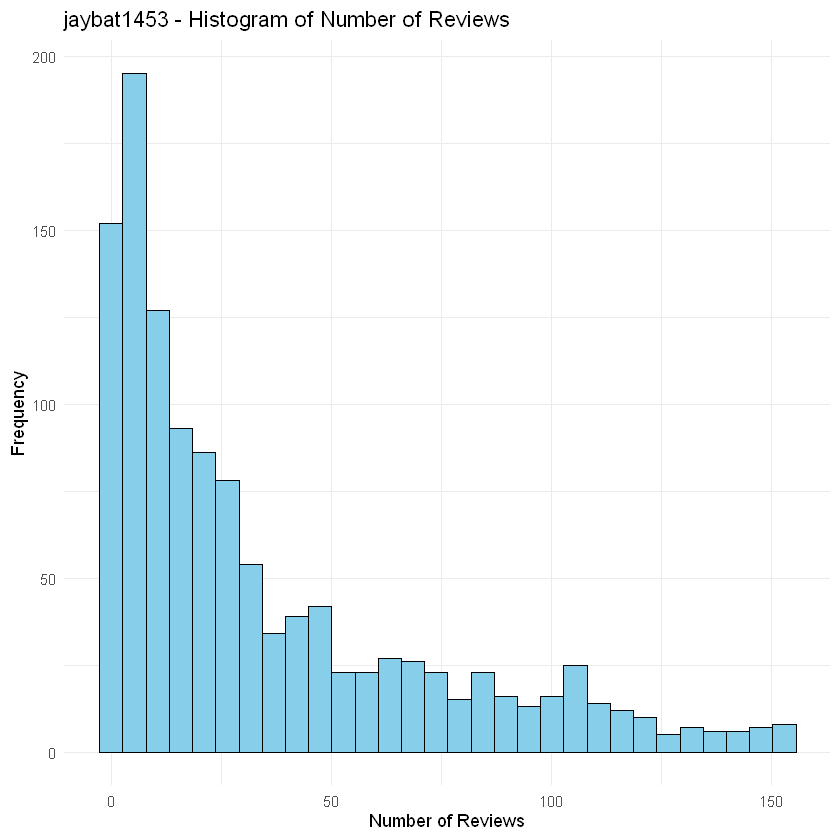

In [7]:
ggplot(df, aes(x = number_of_reviews)) +
  geom_histogram(bins = 30, color = "black", fill = "skyblue") +
  labs(title = "jaybat1453 - Histogram of Number of Reviews",
       x = "Number of Reviews", y = "Frequency") +
  theme_minimal()

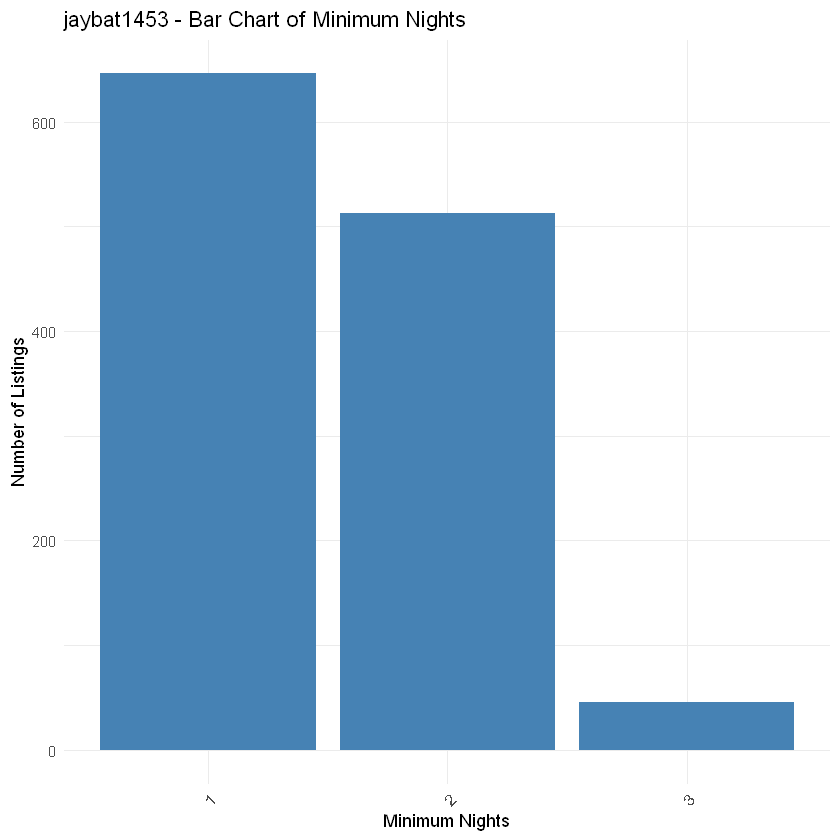

In [8]:
ggplot(df, aes(x = factor(minimum_nights))) +
  geom_bar(fill = "steelblue") +
  labs(title = "jaybat1453 - Bar Chart of Minimum Nights",
       x = "Minimum Nights", y = "Number of Listings") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

`geom_smooth()` using formula = 'y ~ x'


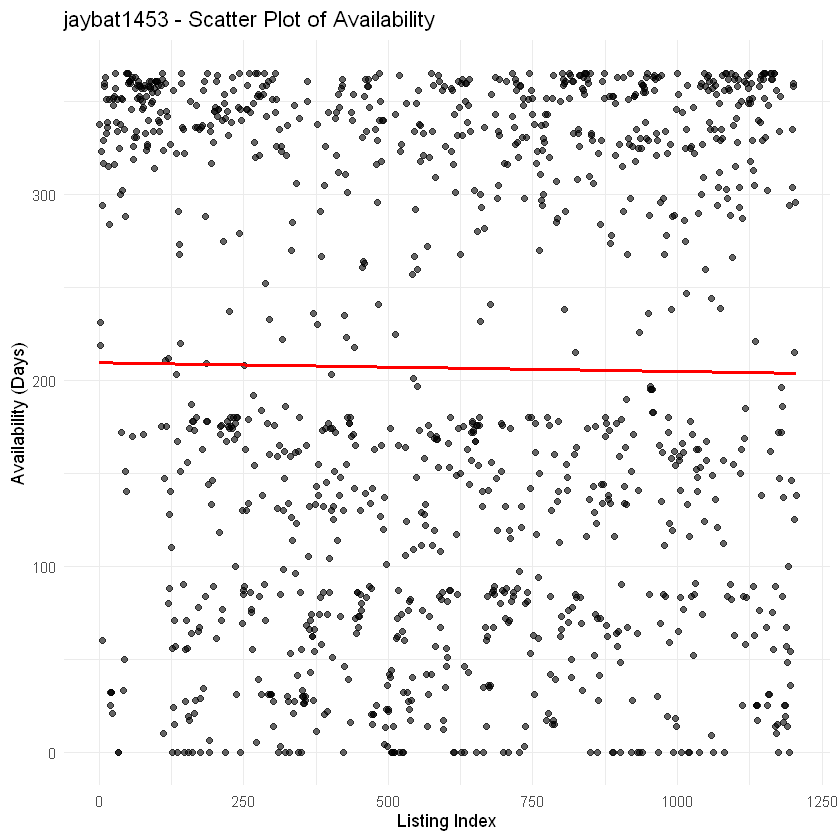

In [9]:
# With one variable specified, use listing row number as the x-axis.
# The line describes availability across row order, not a causal relationship.
plot_df <- data.frame(
  listing_index = seq_len(nrow(df)),
  availability_365 = df$availability_365
)

ggplot(plot_df, aes(x = listing_index, y = availability_365)) +
  geom_point(alpha = 0.6) +
  geom_smooth(method = "lm", se = FALSE, color = "red") +
  labs(title = "jaybat1453 - Scatter Plot of Availability",
       x = "Listing Index", y = "Availability (Days)") +
  theme_minimal()

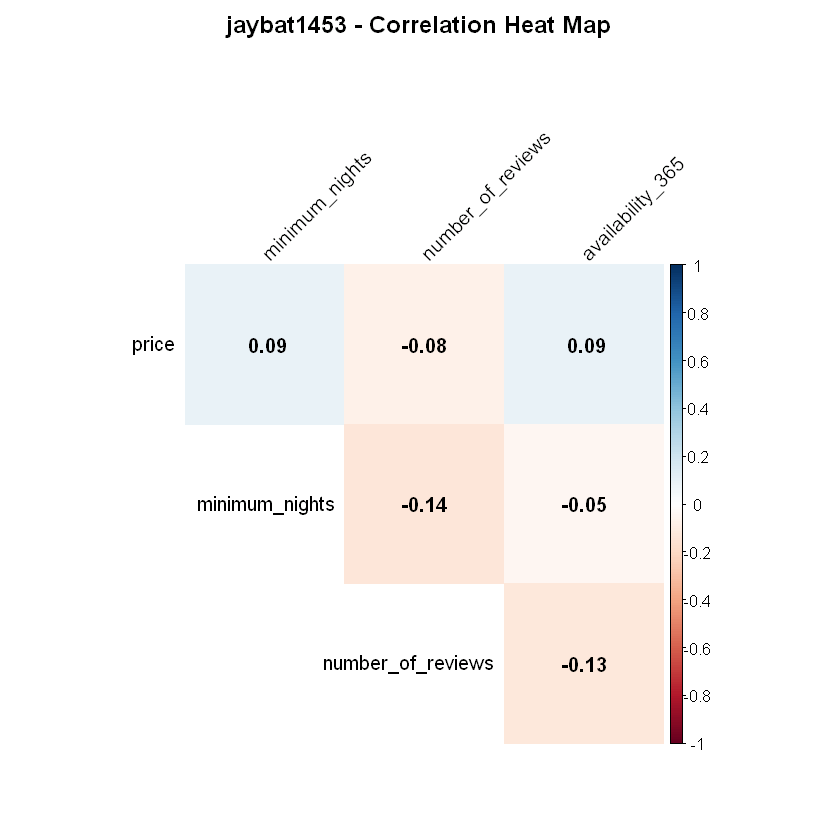

In [10]:
corr_data <- df %>%
  select(price, minimum_nights, number_of_reviews, availability_365)

corr_matrix <- cor(corr_data, use = "complete.obs")

# corrplot parameters:
# method = "color": show correlations as colored squares
# type = "upper": display only the upper triangle
# addCoef.col = "black": print correlation values in black
# tl.col = "black": variable-label color
# tl.srt = 45: rotate variable labels 45 degrees
# diag = FALSE: omit the diagonal self-correlations
corrplot(corr_matrix,
         method = "color",
         type = "upper",
         addCoef.col = "black",
         tl.col = "black",
         tl.srt = 45,
         diag = FALSE,
         title = "jaybat1453 - Correlation Heat Map",
         mar = c(0, 0, 2, 0))